In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import learning_curve

In [3]:
df = pd.read_csv("../data/Churn_Modelling.csv")
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

categorical_features = ["Geography", "Gender"]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

crossValidation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [4]:
depths = [1, 2, 3, 5, 10, 20]
train_accuracies = []
validation_accuracies = []

for depth in depths:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                criterion="entropy",
                random_state=42
            ))
        ]
    )

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=crossValidation,
        scoring="accuracy",
        return_train_score=True
    )

    train_accuracies.append(results["train_score"].mean())
    validation_accuracies.append(results["test_score"].mean())

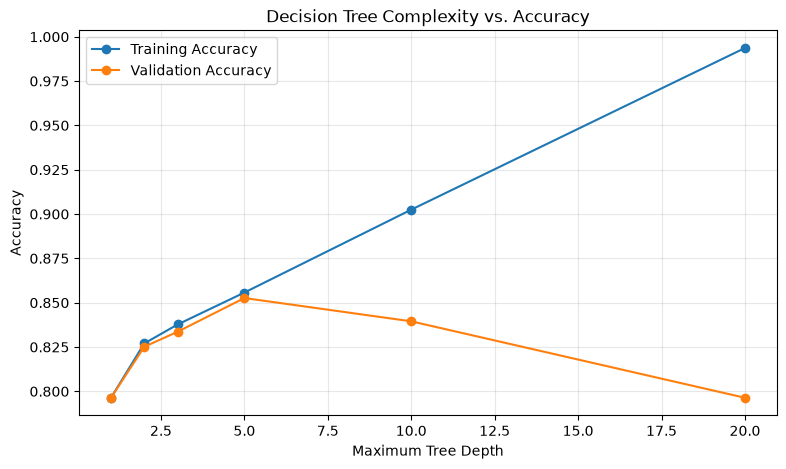

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    validation_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Complexity vs. Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
depths = [1, 2, 3, 5, 10, 20]
validation_f1 = []
validation_recall = []

for depth in depths:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                criterion="entropy",
                random_state=42
            ))
        ]
    )

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=crossValidation,
        scoring=["f1", "recall"]
    )

    validation_f1.append(results["test_f1"].mean())
    validation_recall.append(results["test_recall"].mean())

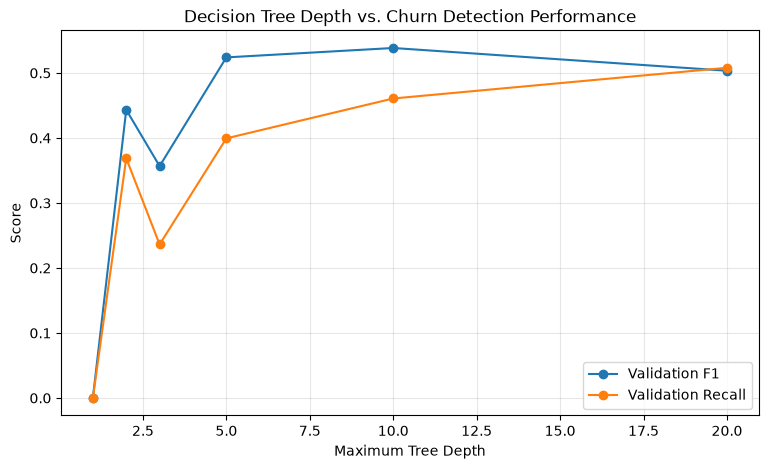

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    validation_f1,
    marker="o",
    label="Validation F1"
)

plt.plot(
    depths,
    validation_recall,
    marker="o",
    label="Validation Recall"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.title("Decision Tree Depth vs. Churn Detection Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
depths = [5, 10, 20]
comparison_results = []

for depth in depths:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                criterion="entropy",
                random_state=42
            ))
        ]
    )

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=crossValidation,
        scoring=["accuracy", "precision", "recall", "f1"],
        return_train_score=True
    )

    comparison_results.append({
        "Depth": depth,
        "Train Accuracy": results["train_accuracy"].mean(),
        "Validation Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "F1 Std": results["test_f1"].std()
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df.round(4)

,Depth,Train Accuracy,Validation Accuracy,Precision,Recall,F1,F1 Std
0,5,0.8557,0.8526,0.7751,0.3994,0.5239,0.0230
1,10,0.9025,0.8395,0.6493,0.4607,0.5384,0.0292
2,20,0.9937,0.7964,0.4995,0.5080,0.5034,0.0296


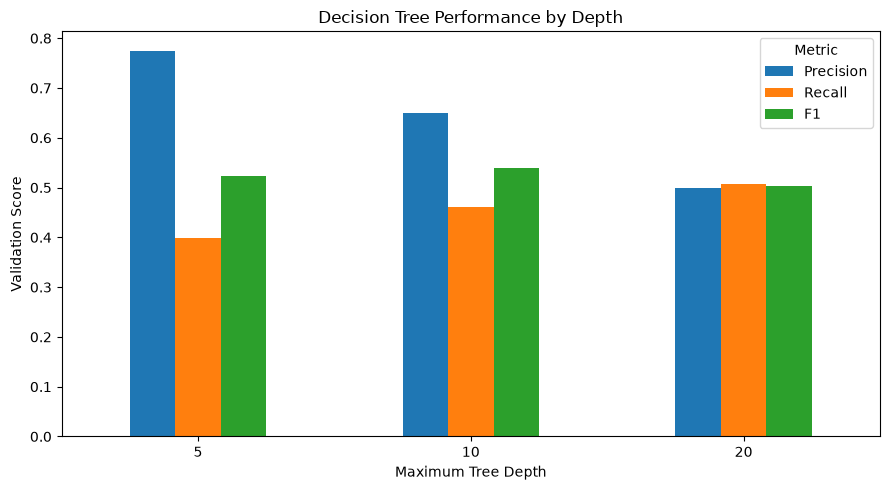

In [9]:
metrics = ["Precision", "Recall", "F1"]

comparison_df.plot(
    x="Depth",
    y=metrics,
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Decision Tree Performance by Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Validation Score")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [12]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            criterion="entropy",
            random_state=42
        ))
    ]
)

train_sizes, train_scores, validation_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=crossValidation,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 10),
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

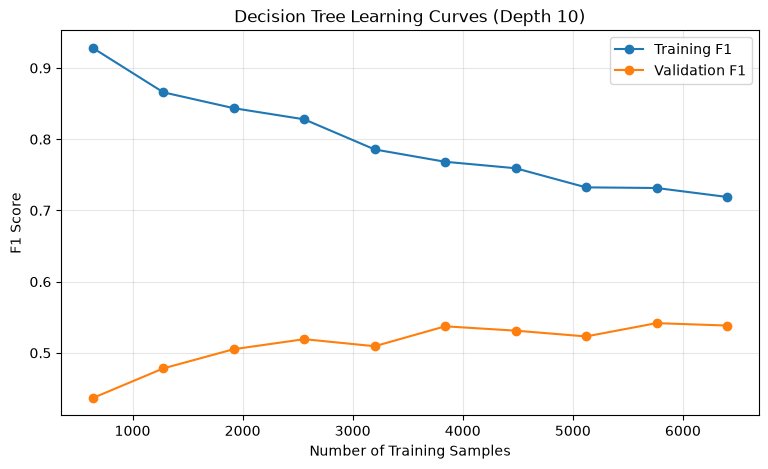

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("F1 Score")
plt.title("Decision Tree Learning Curves (Depth 10)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()